[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/aasfaw-quera/quantum-programming-talk/blob/main/elements-of-quantum-programming-cirq.ipynb) [![Binder](https://mybinder.org/badge_logo.svg)](https://mybinder.org/v2/gh/aasfaw-quera/quantum-programming-talk/main?labpath=elements-of-quantum-programming-cirq.ipynb)

# Tutorial on Quantum Programming: An Introduction

### Earlier: <br/>1/3 Motivation: Why Quantum Computing?
### Now: <br/>2/3 Elements of Quantum Programming
### Next: <br/> 3/3 Solving Problems with Quantum Programs

### `Abraham Asfaw`, QuEra <br/> twitter: `@abe_asfaw`<br/> github: `@aasfaw-quera`
### Notebook & helpers: [github.com/aasfaw-quera/quantum-programming-talk](https://github.com/aasfaw-quera/quantum-programming-talk)
<center><img src='https://raw.githubusercontent.com/aasfaw-quera/quantum-programming-talk/main/images/github-screenshot.png'></center>

# Problem: How would you find the marked number in this box?

<br/>
<center><img src='https://raw.githubusercontent.com/aasfaw-quera/quantum-programming-talk/main/images/box.png'></center>

# Problem: How would you find the marked number in this box?

<br/>
<center><img src='https://raw.githubusercontent.com/aasfaw-quera/quantum-programming-talk/main/images/quantumvsclassical.png'></center>

### Quantum programming allows us to reduce the worst-case number of attempts from exactly the size of the problem to ~square-root of the size of the problem.

# Elements of Quantum Programming

In [1]:
# Installs this talk's helper functions (and Cirq) if they aren't already available.
# Works the same in Colab, Binder, and your own Jupyter.
try:
    import marked_number_boxes, quantum_plots
except ImportError:
    %pip install -q git+https://github.com/aasfaw-quera/quantum-programming-talk.git

import numpy as np
import matplotlib.pyplot as plotter

import warnings
warnings.filterwarnings('ignore')

In [2]:
from marked_number_boxes import quantum_box, find_number_in_quantum_box

max_number = 8
my_box = quantum_box(max_number, print_self = True)

This is a quantum box containing the marked number 8.


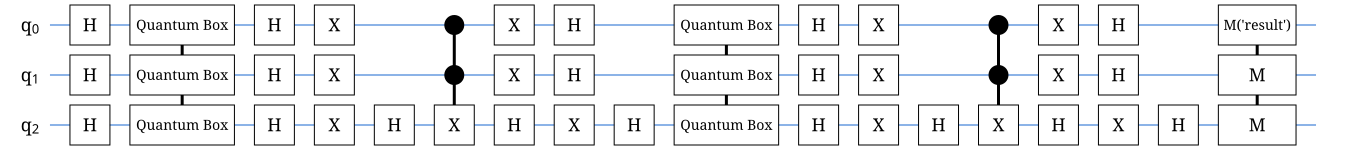

In [3]:
from quantum_plots import draw_circuit

quantum_program = find_number_in_quantum_box(my_box)
draw_circuit(quantum_program)

Each gate in the circuit above is, in itself, translated to control signals that manipulate the quantum states on the physical qubits.

# Key concepts

1. The ability to create `superpositions` and `interfere` them
2. The ability to `entangle` multiple qubits

# 1. The ability to create `superpositions` and `interfere` them

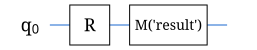

In [4]:
import cirq

number_of_qubits = 1
qubits = cirq.LineQubit.range(number_of_qubits)
my_circuit = cirq.Circuit()

my_circuit.append(cirq.reset(qubits[0]))
my_circuit.append(cirq.measure(*qubits, key='result'))

draw_circuit(my_circuit)

{'0': 10000}


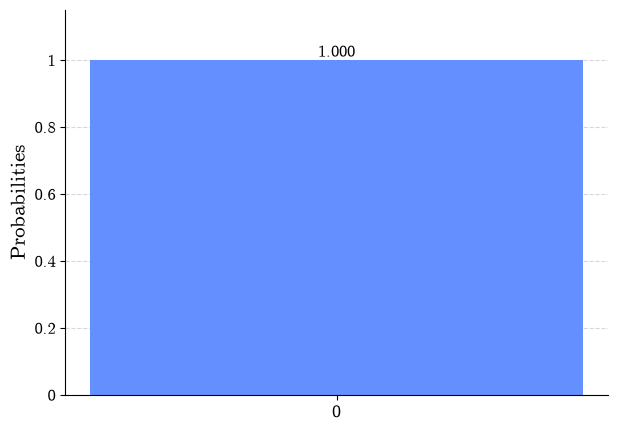

In [5]:
def bits_to_string(bits):
    return ''.join(str(b) for b in bits)

simulator = cirq.Simulator()
counts = simulator.run(my_circuit, repetitions=10000).histogram(key='result', fold_func=bits_to_string)

from quantum_plots import plot_histogram
print(dict(counts))
plot_histogram(counts)

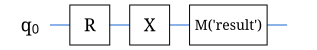

{'1': 10000}


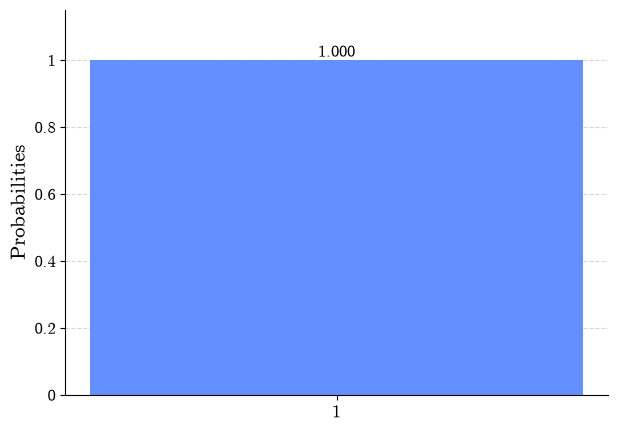

In [6]:
my_circuit = cirq.Circuit()

my_circuit.append(cirq.reset(qubits[0]))
my_circuit.append(cirq.X(qubits[0]))
my_circuit.append(cirq.measure(*qubits, key='result'))

display(draw_circuit(my_circuit))

simulator = cirq.Simulator()
counts = simulator.run(my_circuit, repetitions=10000).histogram(key='result', fold_func=bits_to_string)

print(dict(counts))
plot_histogram(counts)

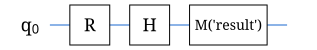

{'0': 5031, '1': 4969}


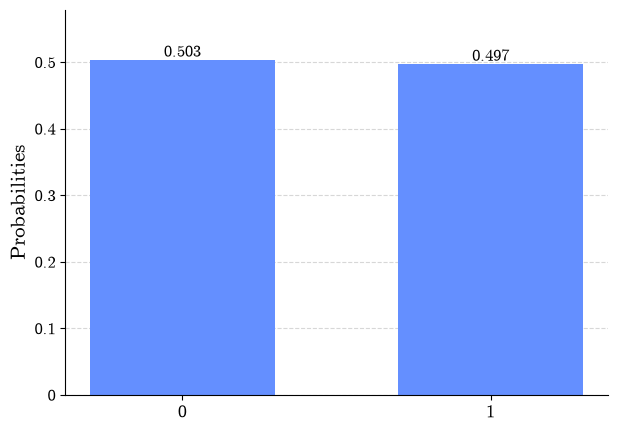

In [7]:
my_circuit = cirq.Circuit()

my_circuit.append(cirq.reset(qubits[0]))
my_circuit.append(cirq.H(qubits[0]))
my_circuit.append(cirq.measure(*qubits, key='result'))

display(draw_circuit(my_circuit))

simulator = cirq.Simulator()
counts = simulator.run(my_circuit, repetitions=10000).histogram(key='result', fold_func=bits_to_string)

print(dict(counts))
plot_histogram(counts)

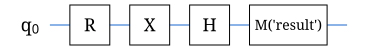

{'0': 5039, '1': 4961}


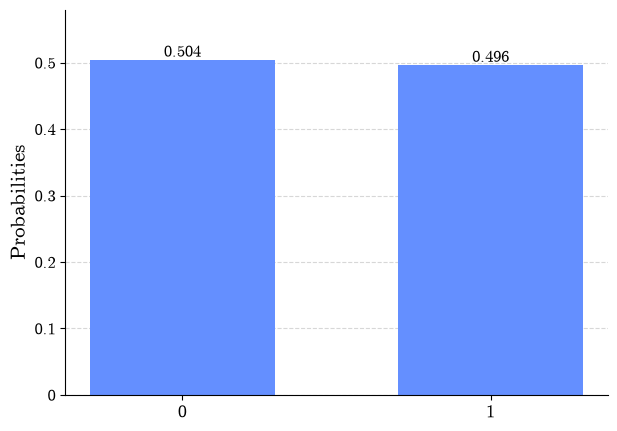

In [8]:
my_circuit = cirq.Circuit()

my_circuit.append(cirq.reset(qubits[0]))
my_circuit.append(cirq.X(qubits[0]))
my_circuit.append(cirq.H(qubits[0]))
my_circuit.append(cirq.measure(*qubits, key='result'))

display(draw_circuit(my_circuit))

simulator = cirq.Simulator()
counts = simulator.run(my_circuit, repetitions=10000).histogram(key='result', fold_func=bits_to_string)

print(dict(counts))
plot_histogram(counts)

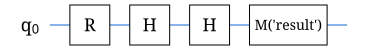

In [9]:
my_circuit = cirq.Circuit()

my_circuit.append(cirq.reset(qubits[0]))
my_circuit.append(cirq.H(qubits[0]))
my_circuit.append(cirq.H(qubits[0]))
my_circuit.append(cirq.measure(*qubits, key='result'))

display(draw_circuit(my_circuit))

{'0': 10000}


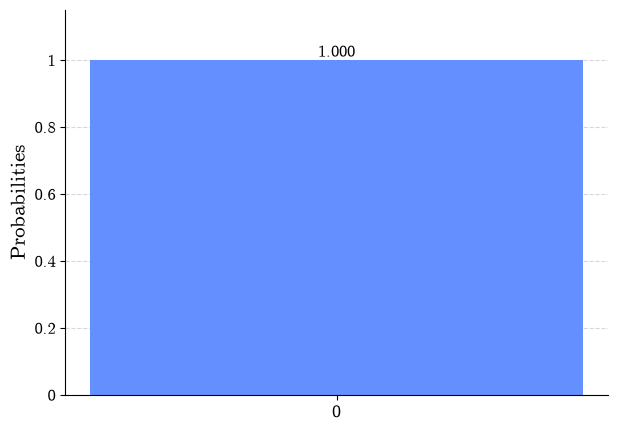

In [10]:
simulator = cirq.Simulator()
counts = simulator.run(my_circuit, repetitions=10000).histogram(key='result', fold_func=bits_to_string)

print(dict(counts))
plot_histogram(counts)

## What happened?

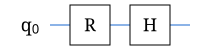

In [11]:
my_circuit = cirq.Circuit()

my_circuit.append(cirq.reset(qubits[0]))
my_circuit.append(cirq.H(qubits[0]))

draw_circuit(my_circuit)

In [12]:
quantum_state = cirq.Simulator().simulate(my_circuit).final_state_vector

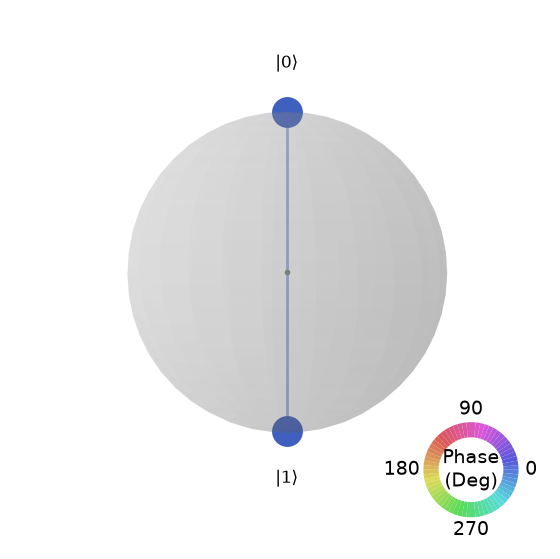

In [13]:
from quantum_plots import plot_state_qsphere

plot_state_qsphere(quantum_state, use_degrees=True)

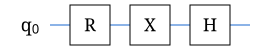

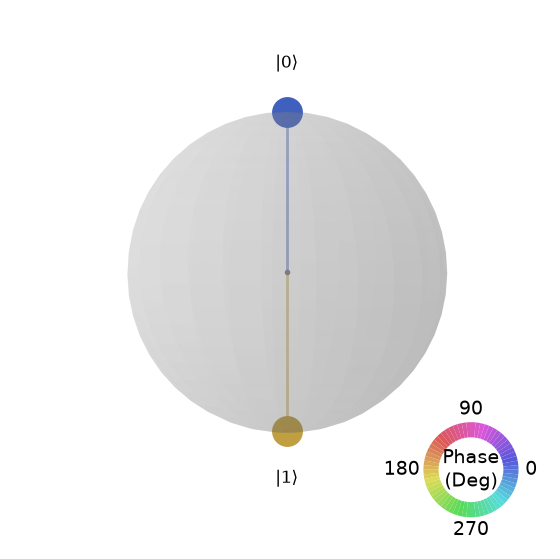

In [14]:
my_circuit = cirq.Circuit()

my_circuit.append(cirq.reset(qubits[0]))
my_circuit.append(cirq.X(qubits[0]))
my_circuit.append(cirq.H(qubits[0]))

display(draw_circuit(my_circuit))

quantum_state = cirq.Simulator().simulate(my_circuit).final_state_vector
plot_state_qsphere(quantum_state, use_degrees=True)

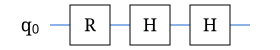

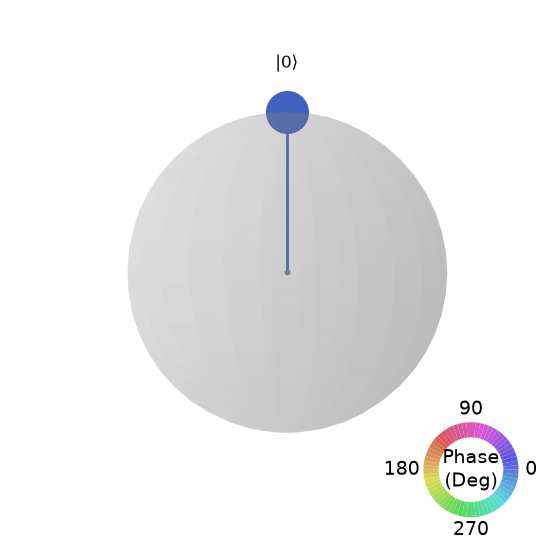

In [15]:
my_circuit = cirq.Circuit()

my_circuit.append(cirq.reset(qubits[0]))
my_circuit.append(cirq.H(qubits[0]))
my_circuit.append(cirq.H(qubits[0]))

display(draw_circuit(my_circuit))

quantum_state = cirq.Simulator().simulate(my_circuit).final_state_vector
plot_state_qsphere(quantum_state, use_degrees=True)

<center><img src='https://raw.githubusercontent.com/aasfaw-quera/quantum-programming-talk/main/images/interference.png'></center>

## `Superpositions` with multiple qubits

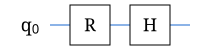

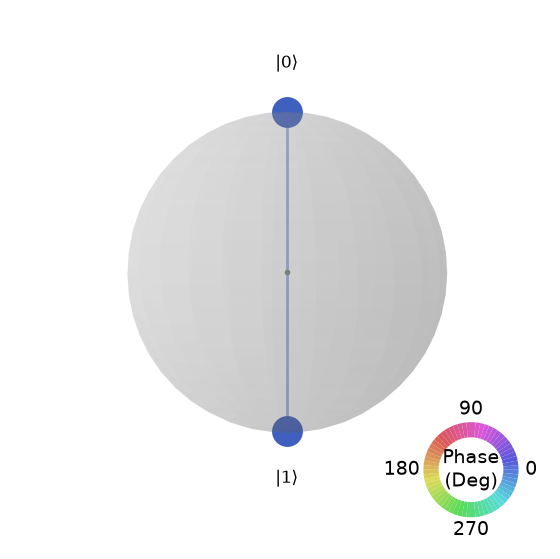

In [16]:
number_of_qubits = 1 # can do even more qubits

qubits = cirq.LineQubit.range(number_of_qubits)
my_circuit = cirq.Circuit()

my_circuit.append(cirq.reset_each(*qubits))
my_circuit.append(cirq.H.on_each(qubits))

display(draw_circuit(my_circuit))

quantum_state = cirq.Simulator().simulate(my_circuit).final_state_vector
plot_state_qsphere(quantum_state, use_degrees=True)

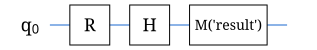

{'0': 5019, '1': 4981}


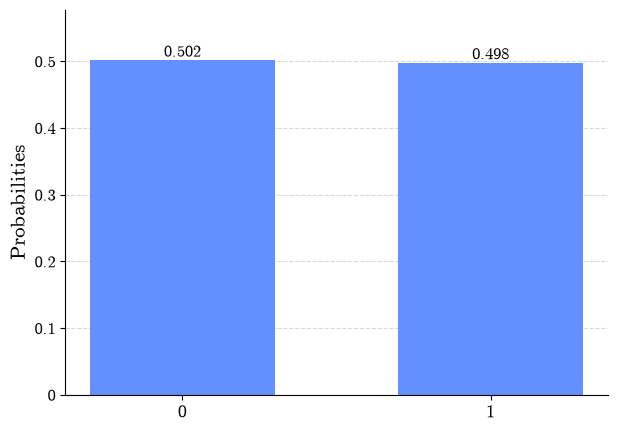

In [17]:
my_circuit.append(cirq.measure(*qubits, key='result'))

display(draw_circuit(my_circuit))

simulator = cirq.Simulator()
counts = simulator.run(my_circuit, repetitions=10000).histogram(key='result', fold_func=bits_to_string)

print(dict(counts))
plot_histogram(counts)

### Just because we can create `superpositions` doesn't mean we can quickly try all possible solutions and get a desired result. All outcomes are equally likely during measurement.

# 2. The ability to `entangle` multiple qubits

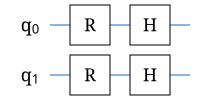

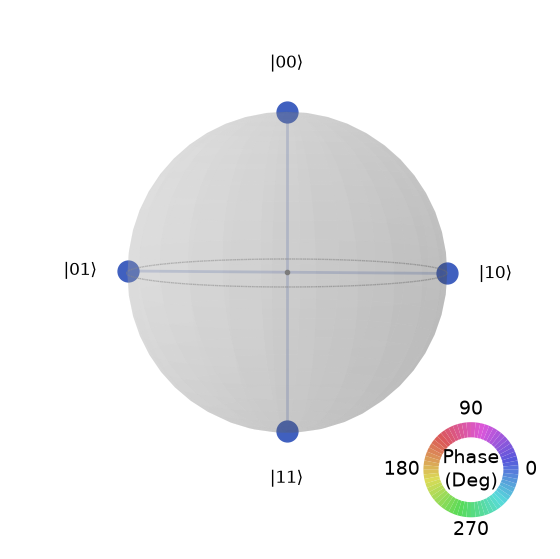

In [18]:
number_of_qubits = 2

qubits = cirq.LineQubit.range(number_of_qubits)
my_circuit = cirq.Circuit()

my_circuit.append(cirq.reset_each(*qubits))
my_circuit.append(cirq.H.on_each(qubits))

display(draw_circuit(my_circuit))

quantum_state = cirq.Simulator().simulate(my_circuit).final_state_vector
plot_state_qsphere(quantum_state, use_degrees=True)

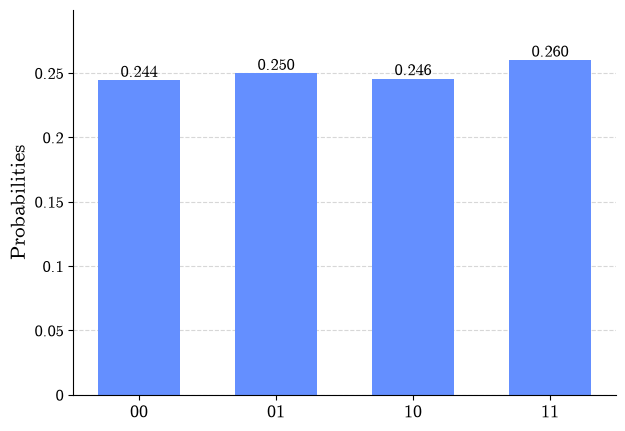

In [19]:
from quantum_plots import sample_counts

plot_histogram(sample_counts(quantum_state, shots=10000))

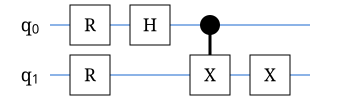

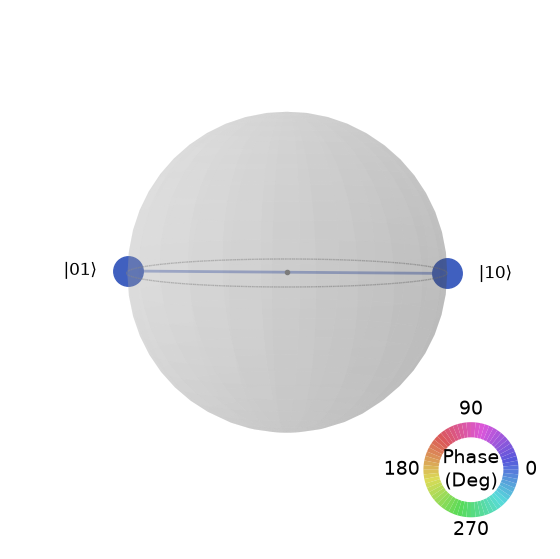

In [20]:
number_of_qubits = 2

qubits = cirq.LineQubit.range(number_of_qubits)
my_circuit = cirq.Circuit()

my_circuit.append(cirq.reset_each(*qubits))
my_circuit.append(cirq.H(qubits[0]))
my_circuit.append(cirq.CNOT(qubits[0], qubits[1]))
my_circuit.append(cirq.X(qubits[1]))

display(draw_circuit(my_circuit))

quantum_state = cirq.Simulator().simulate(my_circuit).final_state_vector
plot_state_qsphere(quantum_state, use_degrees=True)

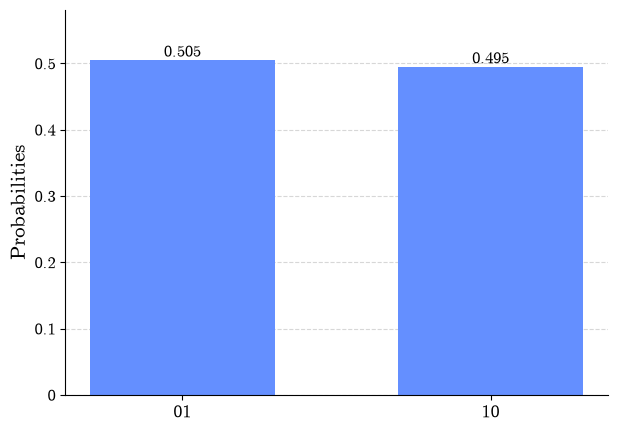

In [21]:
plot_histogram(sample_counts(quantum_state, shots=10000))

# `Superposition`, `interference` and `entanglement` in action
Remember the unstructured search problem?

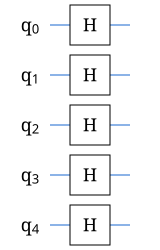

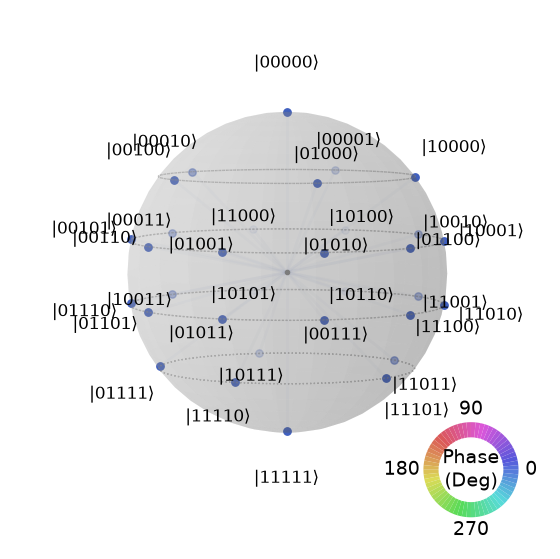

In [22]:
from marked_number_boxes import quantum_box, search_steps

my_box = quantum_box(32)

quantum_program = search_steps(my_box, 0)
display(draw_circuit(quantum_program))

quantum_state = cirq.Simulator().simulate(quantum_program).final_state_vector
plot_state_qsphere(quantum_state, use_degrees=True)

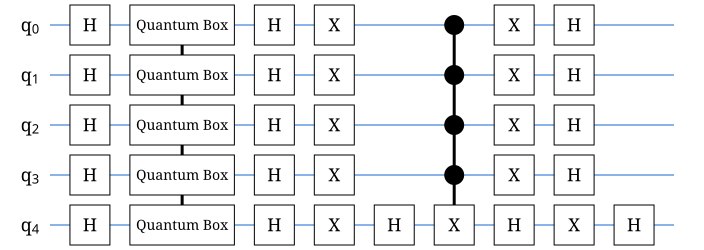

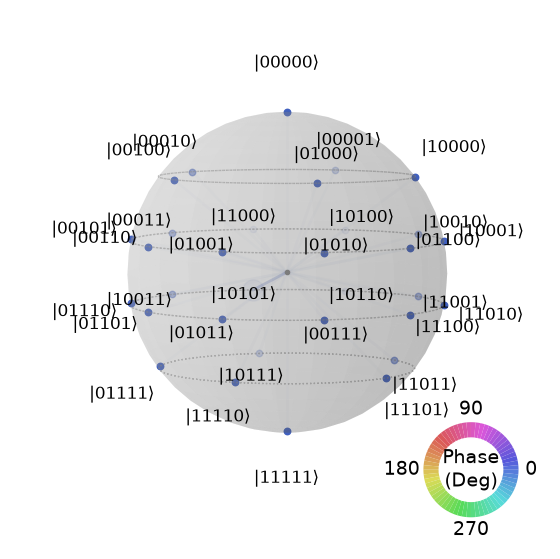

In [23]:
quantum_program = search_steps(my_box, 1)
display(draw_circuit(quantum_program))

quantum_state = cirq.Simulator().simulate(quantum_program).final_state_vector
plot_state_qsphere(quantum_state, use_degrees=True)

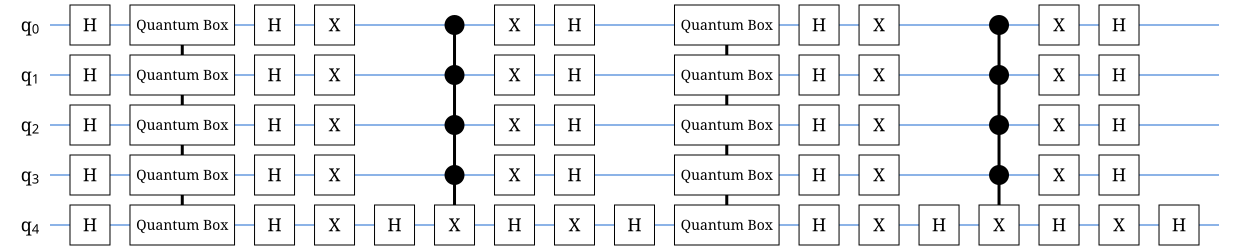

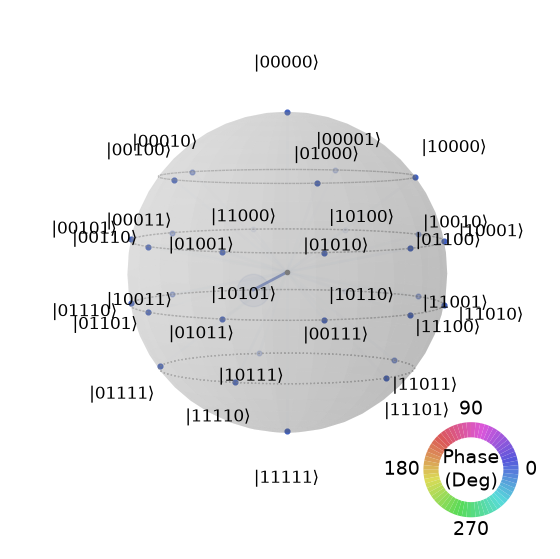

In [24]:
quantum_program = search_steps(my_box, 2)
display(draw_circuit(quantum_program))

quantum_state = cirq.Simulator().simulate(quantum_program).final_state_vector
plot_state_qsphere(quantum_state, use_degrees=True)

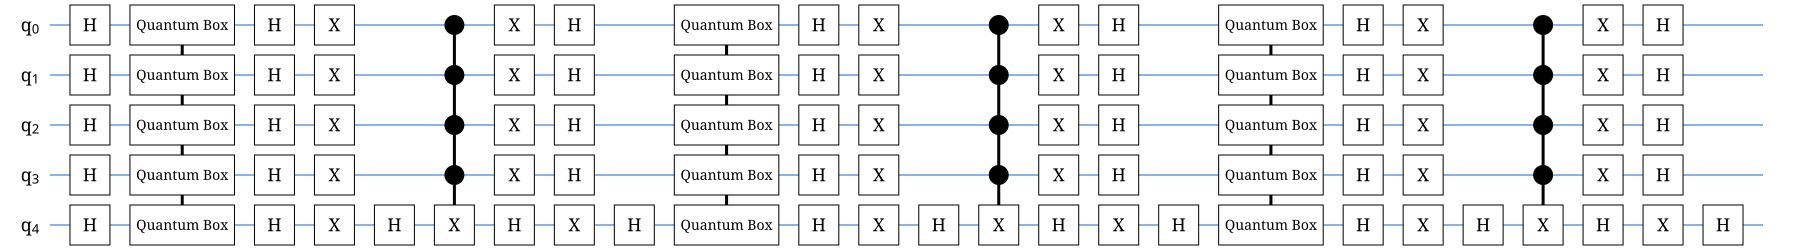

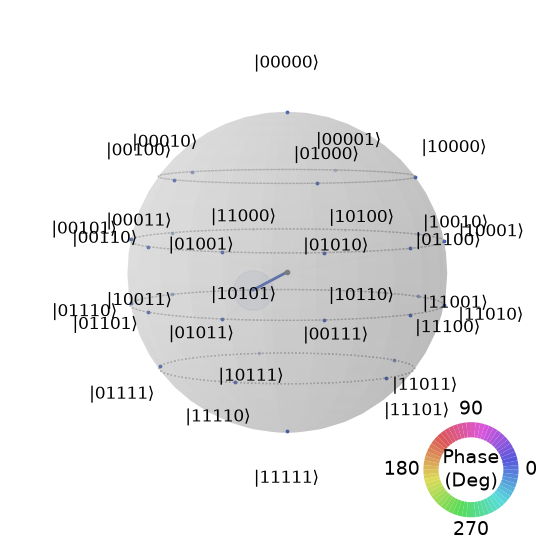

In [25]:
quantum_program = search_steps(my_box, 3)
display(draw_circuit(quantum_program))

quantum_state = cirq.Simulator().simulate(quantum_program).final_state_vector
plot_state_qsphere(quantum_state, use_degrees=True)

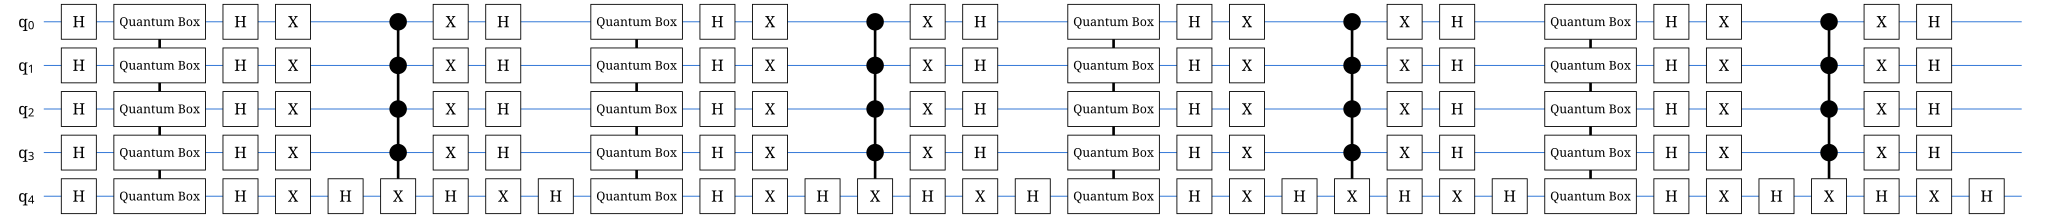

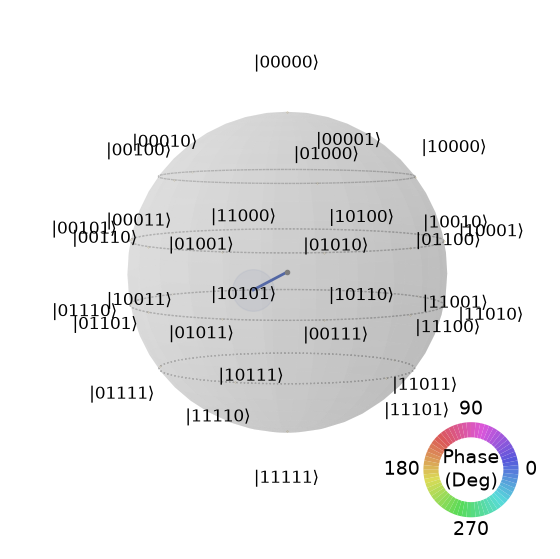

In [26]:
quantum_program = search_steps(my_box, 4)
display(draw_circuit(quantum_program))

quantum_state = cirq.Simulator().simulate(quantum_program).final_state_vector
plot_state_qsphere(quantum_state, use_degrees=True)

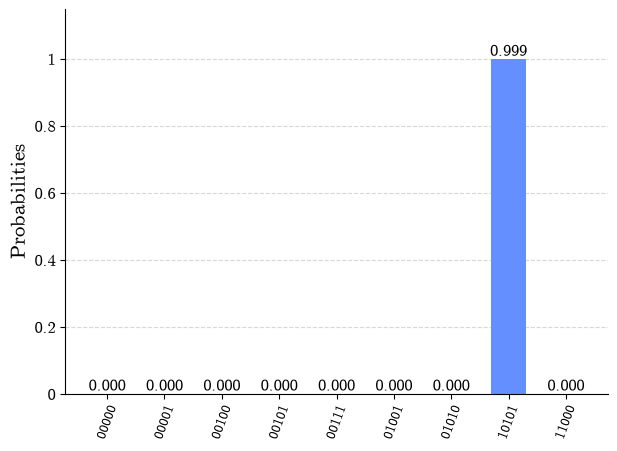

In [27]:
plot_histogram(sample_counts(quantum_state, shots=10000))